# Warp priority selection

SM7_QV100 · Rodinia NN and Hotspot · four scheduler policies. The feasibility sweep follows the cap experiment.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

LAUNCH_CSV = None  # "results/adaptive_policy/launch_counters.csv"
EXPERIMENT_CSV = "results/adaptive_policy/nn_hotspot_limit4.csv"

WORKLOADS = ["backprop", "nn", "heartwall", "hotspot"]
WORKLOAD_NAMES = {"backprop": "Backprop", "nn": "NN", "heartwall": "Heartwall", "hotspot": "Hotspot"}
POLICY_NAMES = {"lrr": "LRR", "gto": "GTO", "oldest": "Oldest First", "gto_limit4": "GTO limit 4"}
POLICY_COLORS = {"gto": "#326a91", "oldest": "#af562f", "gto_limit4": "#357c66"}

def input_path(value):
    path = Path(value).expanduser()
    if path.is_absolute() or path.is_file():
        return path
    return Path.cwd().parent / path

pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})

## GTO limit 4 on NN and Hotspot

After four successful issue cycles from the same dynamic warp, the scheduler orders by age. The cap can stay active across several cycles. Counts sum scheduler cycles across cores and schedulers.

policy,LRR,GTO,Oldest First,GTO limit 4,Limit 4 − GTO (cycles),Change vs. GTO (%)
workload,,,,,,
NN,30277,30482,29687,30520,38,0.12
Hotspot,54287,53797,54098,53826,29,0.05


,Cap-active scheduler cycles,Active cycles issuing another warp,Other warp / active (%)
workload,,,
NN,1872041,40541,2.17
Hotspot,2303404,135868,5.90


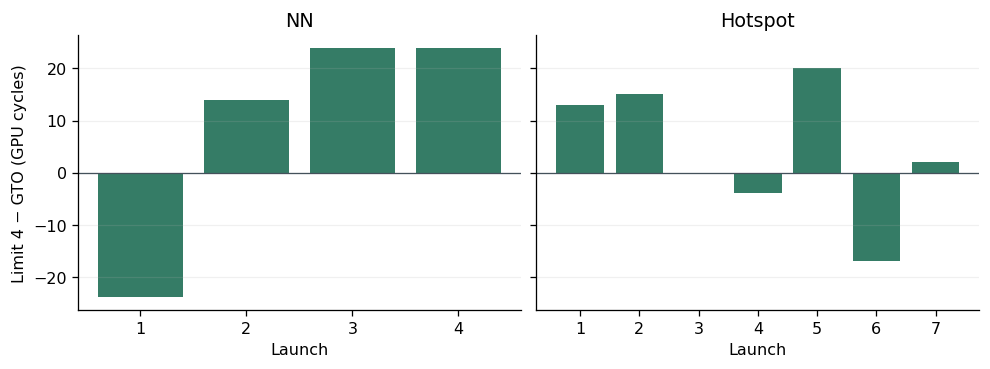

In [2]:
experiment = pd.read_csv(input_path(EXPERIMENT_CSV))
policies = ["lrr", "gto", "oldest", "gto_limit4"]
launch_counts = {"nn": 4, "hotspot": 7}
expected = {(w, p, i) for w, n in launch_counts.items()
            for p in policies for i in range(1, n + 1)}
keys = ["workload", "policy", "launch"]
assert len(experiment) == len(expected) and set(experiment[keys].itertuples(index=False, name=None)) == expected
paired = experiment.groupby(["workload", "launch"])[["kernel", "instructions"]]
assert experiment[["kernel", "instructions", "cycles"]].notna().all().all()
assert paired.nunique().eq(1).all().all()

cycle_data = experiment.groupby(["workload", "policy"]).cycles.sum().unstack()
cycle_data = cycle_data.loc[list(launch_counts), policies]
comparison = cycle_data.rename(index=WORKLOAD_NAMES, columns=POLICY_NAMES).copy()
comparison["Limit 4 − GTO (cycles)"] = comparison["GTO limit 4"] - comparison["GTO"]
comparison["Change vs. GTO (%)"] = (100 * comparison["Limit 4 − GTO (cycles)"] / comparison["GTO"]).round(2)
display(comparison)

limited = experiment[experiment.policy.eq("gto_limit4")]
active = "limit_active_cycles"
other = "limit_other_warp_cycles"
assert limited[[active, other]].notna().all().all()
assert limited[other].between(0, limited[active]).all()
cap = limited.groupby("workload")[[active, other]].sum().loc[list(launch_counts)].astype(int)
cap["Other warp / active (%)"] = (100 * cap[other] / cap[active]).round(2)
display(cap.rename(index=WORKLOAD_NAMES, columns={active: "Cap-active scheduler cycles",
                                                  other: "Active cycles issuing another warp"}))

launches = experiment.pivot(index=["workload", "launch"], columns="policy", values="cycles")
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.1), sharey=True, layout="constrained")
for ax, workload in zip(axes, launch_counts):
    rows = launches.loc[workload]
    delta = rows["gto_limit4"] - rows["gto"]
    ax.bar(rows.index, delta, color=POLICY_COLORS["gto_limit4"])
    ax.axhline(0, color="#44515b", linewidth=0.8)
    ax.set(title=WORKLOAD_NAMES[workload], xlabel="Launch", xticks=rows.index)
    ax.grid(axis="y", alpha=0.18)
axes[0].set_ylabel("Limit 4 − GTO (GPU cycles)")
plt.show()

Limit 4 added 38 GPU cycles on NN and 29 on Hotspot versus GTO. Oldest First led NN. On Hotspot, limit 4 retained a 272-cycle lead over Oldest First.

## Launch counter changes relative to stock GTO

Each pair has the same workload, launch index, kernel and instruction count. Idle and scoreboard count scheduler observations. Load/store stalls count events at the memory pipeline.

In [3]:
metrics = ["cycles", "idle", "scoreboard", "ldst_stalls"]
match = ["workload", "launch", "kernel", "instructions"]
by_policy = experiment.set_index(match + ["policy"])[metrics].unstack("policy")
stock = by_policy.xs("gto", axis=1, level="policy")
deltas = {POLICY_NAMES[p]: by_policy.xs(p, axis=1, level="policy") - stock
          for p in ["oldest", "gto_limit4"]}
paired_changes = pd.concat(deltas, axis=1).droplevel(["kernel", "instructions"])
display(paired_changes.loc[list(launch_counts)])

Oldest First                               GTO limit 4        \
                      cycles   idle scoreboard ldst_stalls      cycles  idle   
workload launch                                                                
nn       1              -189  -3466     -75195         975         -24 -4382   
         2              -194  -9259     -54894        2054          14  -407   
         3              -179  -9293     -53992        2285          24 -3767   
         4              -233 -17860     -54741        2214          24 -7703   
hotspot  1                93   5462      -4604          70          13  3051   
         2                55  10349      -3145           0          15  3817   
         3                38  10074      -6992           0           0  5158   
         4                38   8707      -7922           0          -4  3851   
         5                30   9851      -6025           0          20  4032   
         6                11   9725      -9995           0         -17  4338   
         7                36   4048      -2586           0           2  1360   

                                        
                scoreboard ldst_stalls  
workload launch                         
nn       1           -6959          79  
         2          -11177         326  
         3           -5016         549  
         4            1409         445  
hotspot  1           -6135           0  
         2          -11240           0  
         3           -4997           0  
         4           -4946           0  
         5           -4316           0  
         6           -8982           0  
         7           -3467           0

On NN launch 1, both policies reduced idle and scoreboard observations and increased load/store stalls. Limit 4 recovered 6,959 of the 75,195 scoreboard observations removed by Oldest First. On launch 4, limit 4 increased scoreboard observations by 1,409.

## Older issue alternatives under stock GTO

A repeat is a successful scheduler cycle issuing from the previous successful dynamic warp. A bypass requires at least one older supervised warp with an issuable head instruction immediately before dispatch. Each eligible older warp accrues one opportunity per bypass until its own next issue. Gaps can intervene. The histogram includes waits with at least one opportunity.

repeats  bypasses  unknown_cycles  opportunities  Bypass (%)
workload launch                                                              
nn       1        147951      6615               0           6835        4.47
         2        143039      8598               0           9039        6.01
         3        142216      8707               0           9140        6.12
         4        141809      9076               0           9538        6.40
hotspot  1        149266     17597               0          17597       11.79
         2        149280     20039               0          20039       13.42
         3        149413     20879               0          20879       13.97
         4        149476     20732               0          20732       13.87
         5        149450     20652               0          20652       13.82
         6        149319     20621               0          20621       13.81
         7         98841     16302               0          16302       16.49

,repeats,bypasses,unknown_cycles,opportunities,Bypass (%),Waits,Waits with ≥2
workload,,,,,,,
NN,575015,32996,0,34552,5.74,17097,9032
Hotspot,995045,136822,0,136822,13.75,41035,32721


,NN,Hotspot
Eligible bypasses before next issue,,
1,8065,8314
2,4914,6961
3,2086,5860
4,1060,8212
5,488,8276
6,137,2512
7,121,41
8,71,561
9,108,109


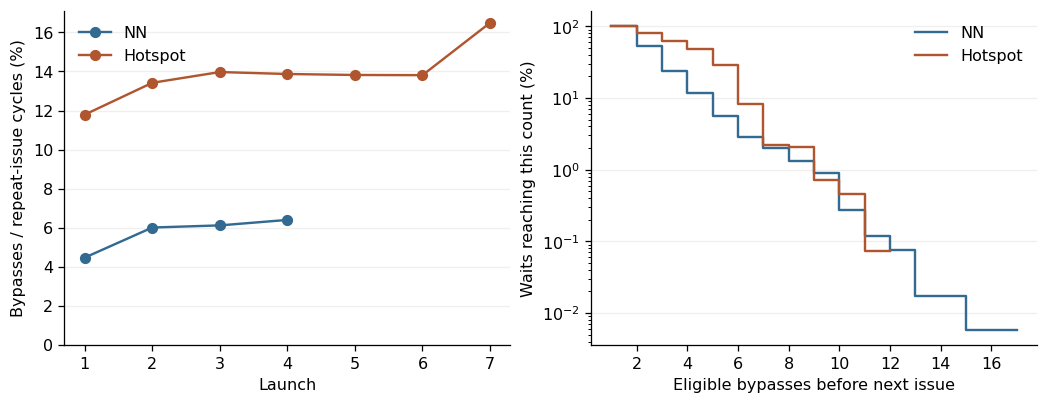

In [4]:
import json
from collections import Counter

diag = pd.read_csv(input_path("results/adaptive_policy/gto_bypass.csv"))
paired_key = ["workload", "launch", "kernel", "instructions", "cycles"]
control = experiment.loc[experiment.policy.eq("gto"), paired_key]
checked = control.merge(diag, on=paired_key, how="outer", validate="one_to_one", indicator=True)
assert checked["_merge"].eq("both").all()
counts = ["repeats", "bypasses", "unknown_cycles", "opportunities"]
by_launch = diag.set_index(["workload", "launch"])[counts]
by_launch["Bypass (%)"] = (100 * by_launch.bypasses / by_launch.repeats).round(2)
display(by_launch)
totals = diag.groupby("workload")[counts].sum().loc[list(launch_counts)]
totals["Bypass (%)"] = (100 * totals.bypasses / totals.repeats).round(2)

histograms = {}
for workload in launch_counts:
    hist = Counter()
    for row in diag[diag.workload.eq(workload)].itertuples():
        waits = {int(k): v for k, v in json.loads(row.wait_histogram).items()}
        assert sum(k * v for k, v in waits.items()) == row.opportunities
        hist.update(waits)
    histograms[workload] = hist
    totals.loc[workload, "Waits"] = sum(hist.values())
    totals.loc[workload, "Waits with ≥2"] = sum(v for k, v in hist.items() if k >= 2)
totals = totals.astype({"Waits": int, "Waits with ≥2": int})
display(totals.rename(index=WORKLOAD_NAMES))

wait_counts = pd.DataFrame(histograms).fillna(0).astype(int).sort_index()
wait_counts = wait_counts.reindex(range(1, wait_counts.index.max() + 1), fill_value=0)
wait_counts.index.name = "Eligible bypasses before next issue"
display(wait_counts.rename(columns=WORKLOAD_NAMES))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained")
for workload, color in zip(launch_counts, ["#326a91", "#af562f"]):
    rates = by_launch.loc[workload, "Bypass (%)"]
    axes[0].plot(rates.index, rates, "o-", color=color, label=WORKLOAD_NAMES[workload])
    freq = wait_counts[workload]
    survival = freq[::-1].cumsum()[::-1] / freq.sum() * 100
    axes[1].step(survival.index[survival.gt(0)], survival[survival.gt(0)],
                 where="post", color=color, label=WORKLOAD_NAMES[workload])
axes[0].set(xlabel="Launch", ylabel="Bypasses / repeat-issue cycles (%)", ylim=(0, None))
axes[1].set(xlabel="Eligible bypasses before next issue", ylabel="Waits reaching this count (%)",
            yscale="log")
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False)
plt.show()

Coverage is limited to repeat-issue cycles on each local scheduler. Stateful barrier, wait-group, nanosleep, CDP or TRYWAIT checks that could affect the answer are recorded in `unknown_cycles`. Multiple older alternatives contribute one bypassed cycle and one opportunity each.

All 11 launches matched stock timing and work. Unknown cycles were zero. Hotspot bypassed an older issuable warp on 13.75% of repeats versus 5.74% on NN. Among positive waits, 79.74% reached two opportunities on Hotspot versus 52.83% on NN. Bypass frequency alone gives no NN-specific rationale for an age override.

## Instructions at stock-GTO bypass decisions

Each repeat issue with an eligible older warp contributes one pair. The alternative is the issuable head of the supervised warp with the smallest dynamic ID. Loads and stores use decoded memory flags. Arithmetic includes integer, floating-point, SFU and tensor operations. Generic ALU instructions (including moves and conversions), branches, barriers and atomics count as other. The CSV includes zero-count and unclassified pairs.

count  % repeats  % bypasses
workload greedy     oldest                                  
hotspot  arithmetic arithmetic  65552      6.588      47.910
                    load          744      0.075       0.544
                    other        6561      0.659       4.795
                    store         154      0.015       0.113
         load       arithmetic   3115      0.313       2.277
                    other         813      0.082       0.594
         other      arithmetic  53514      5.378      39.112
                    load          187      0.019       0.137
                    other        6153      0.618       4.497
                    store          29      0.003       0.021
nn       arithmetic arithmetic  11529      2.005      34.941
                    other        2254      0.392       6.831
                    store         566      0.098       1.715
         load       arithmetic    608      0.106       1.843
                    load         2558      0.445       7.752
                    other          84      0.015       0.255
         other      arithmetic  10443      1.816      31.649
                    load           12      0.002       0.036
                    other        4417      0.768      13.386
                    store         520      0.090       1.576
         store      arithmetic      3      0.001       0.009
                    other           2      0.000       0.006

count  repeats  bypasses  pct_repeats  pct_bypasses
workload launch                                                     
nn       1           0   147951      6615        0.000         0.000
         2           0   143039      8598        0.000         0.000
         3           0   142216      8707        0.000         0.000
         4           0   141809      9076        0.000         0.000
hotspot  1         384   149266     17597        0.257         2.182
         2         160   149280     20039        0.107         0.798
         3          48   149413     20879        0.032         0.230
         4          37   149476     20732        0.025         0.178
         5          54   149450     20652        0.036         0.261
         6          49   149319     20621        0.033         0.238
         7          12    98841     16302        0.012         0.074

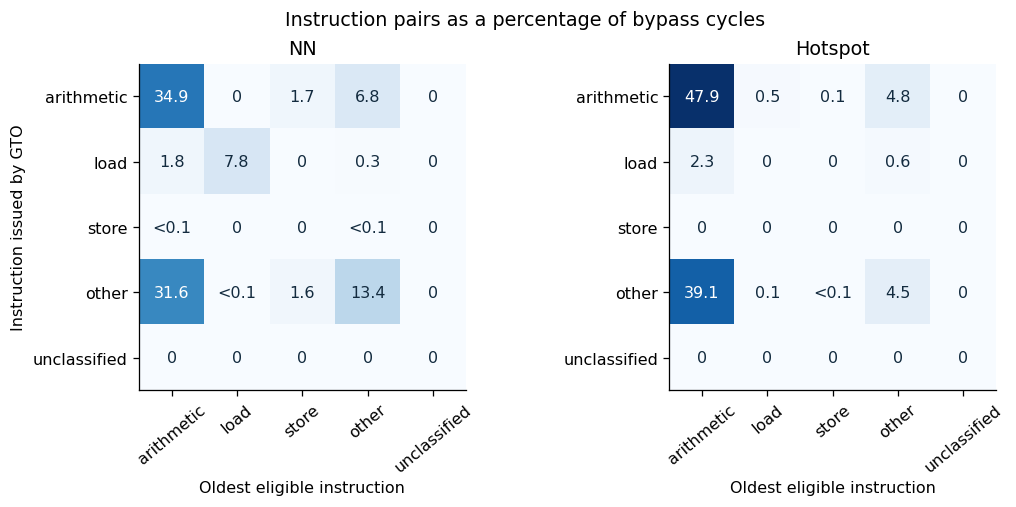

In [5]:
pairs = pd.read_csv(input_path("results/adaptive_policy/gto_pairs.csv"))
launch_key = ["workload", "launch"]
assert not pairs.duplicated(launch_key + ["greedy", "oldest"]).any()
grouped = pairs.groupby(launch_key)
assert grouped.size().eq(25).all()
denoms = diag.set_index(launch_key)[["repeats", "bypasses"]].sort_index()
pd.testing.assert_frame_equal(grouped[["repeats", "bypasses"]].first(), denoms)
assert grouped["count"].sum().equals(denoms.bypasses)
all_pairs = pairs.groupby(["workload", "greedy", "oldest"])[["count"]].sum()
all_pairs = all_pairs.join(denoms.groupby("workload").sum(), on="workload")
all_pairs["% repeats"] = 100 * all_pairs["count"] / all_pairs.repeats
all_pairs["% bypasses"] = 100 * all_pairs["count"] / all_pairs.bypasses
display(all_pairs.loc[all_pairs["count"].gt(0), ["count", "% repeats", "% bypasses"]].round(3))

target = pairs.query('greedy == "arithmetic" and oldest == "load"').set_index(launch_key)
display(target[["count", "repeats", "bypasses", "pct_repeats", "pct_bypasses"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.3), layout="constrained")
classes = ["arithmetic", "load", "store", "other", "unclassified"]
vmax = all_pairs["% bypasses"].max()
for ax, workload in zip(axes, ["nn", "hotspot"]):
    matrix = all_pairs.loc[workload, "% bypasses"].unstack().reindex(index=classes, columns=classes)
    mesh = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=vmax)
    ax.set(title=WORKLOAD_NAMES[workload], xlabel="Oldest eligible instruction",
           xticks=range(5), xticklabels=classes, yticks=range(5), yticklabels=classes)
    ax.tick_params(axis="x", labelrotation=40)
    for y in range(5):
        for x in range(5):
            value = matrix.iloc[y, x]
            label = "0" if value == 0 else ("<0.1" if value < 0.1 else f"{value:.1f}")
            ax.text(x, y, label, ha="center", va="center",
                    color="white" if value > 0.55 * vmax else "#132b3f")
axes[0].set_ylabel("Instruction issued by GTO")
fig.suptitle("Instruction pairs as a percentage of bypass cycles")
plt.show()

Stock timing and work matched on all 11 launches. The arithmetic/load pair occurred on zero of 32,996 NN bypasses. Of the 2,570 NN bypasses whose oldest alternative was a load, GTO issued a load on 2,558 and an “other” operation on 12. Hotspot had 744 arithmetic/load pairs among 136,822 bypasses (0.544%). All pairs were classified, with zero unknown-eligibility cycles. The NN trigger was absent, so the experiment ended at the diagnostic.

## GTO load/load override

During a greedy repeat, promote the oldest eligible older warp only if both head instructions are loads under the pair diagnostic’s classification. The counter increments when that promoted warp actually issues. Baseline pairs were observed under stock GTO. Changes to issue order can change subsequent opportunities.

Load/load pairs  repeats  pct_repeats
workload launch                                       
nn       1                   534   147951       0.3609
         2                   631   143039       0.4411
         3                   724   142216       0.5091
         4                   669   141809       0.4718
hotspot  1                     0   149266       0.0000
         2                     0   149280       0.0000
         3                     0   149413       0.0000
         4                     0   149476       0.0000
         5                     0   149450       0.0000
         6                     0   149319       0.0000
         7                     0    98841       0.0000

,Load/load pairs,repeats,pct_repeats
workload,,,
nn,2558,575015,0.4449
hotspot,0,995045,0.0000


Measured           Enabled − GTO                         \
           cycles overrides        cycles scoreboard ldst_stalls   
workload                                                           
nn          30561       509            79     -57508        1758   
hotspot     53797         0             0          0           0   

         Enabled − Oldest First                         
                         cycles scoreboard ldst_stalls  
workload                                                
nn                          874     181314       -5770  
hotspot                    -301      41269         -70

Measured           Enabled − GTO                         \
                  cycles overrides        cycles scoreboard ldst_stalls   
workload launch                                                           
nn       1          7502       118           -87     -18700         229   
         2          7688       116            66     -20264         427   
         3          7692       127            55     -14075         571   
         4          7679       148            45      -4469         531   
hotspot  1          7765         0             0          0           0   
         2          7894         0             0          0           0   
         3          7765         0             0          0           0   
         4          7775         0             0          0           0   
         5          7759         0             0          0           0   
         6          7782         0             0          0           0   
         7          7057         0             0          0           0   

                Enabled − Oldest First                         
                                cycles scoreboard ldst_stalls  
workload launch                                                
nn       1                         102      56495        -746  
         2                         260      34630       -1627  
         3                         234      39917       -1714  
         4                         278      50272       -1683  
hotspot  1                         -93       4604         -70  
         2                         -55       3145           0  
         3                         -38       6992           0  
         4                         -38       7922           0  
         5                         -30       6025           0  
         6                         -11       9995           0  
         7                         -36       2586           0

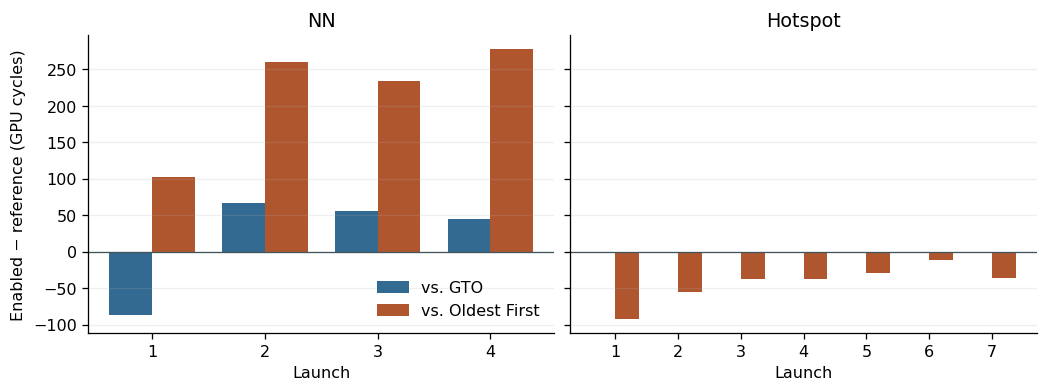

In [6]:
load_pairs = pairs.query('greedy == "load" and oldest == "load"').set_index(["workload", "launch"])
baseline = load_pairs[["count", "repeats"]].rename(columns={"count": "Load/load pairs"})
for counts in (baseline, baseline.groupby("workload", sort=False).sum()):
    display(counts.assign(pct_repeats=(100 * counts["Load/load pairs"] / counts.repeats).round(4)))

load_runs = pd.read_csv(input_path("results/adaptive_policy/gto_load_load.csv"))
key = ["workload", "launch"]
metrics_ll = ["cycles", "scoreboard", "ldst_stalls"]
controls = experiment.set_index(key + ["policy"]).sort_index()
modes = load_runs.set_index(key + ["enabled"]).sort_index()
off = modes.xs(0, level="enabled")
on = modes.xs(1, level="enabled")
stock = controls.xs("gto", level="policy")
oldest = controls.xs("oldest", level="policy")
ident = ["kernel", "instructions"]
pd.testing.assert_frame_equal(off[ident + metrics_ll], stock[ident + metrics_ll])
pd.testing.assert_frame_equal(on[ident], stock[ident])
pd.testing.assert_frame_equal(on[ident], oldest[ident])
assert off.overrides.eq(0).all()
comparison_ll = pd.concat({
    "Measured": on[["cycles", "overrides"]],
    "Enabled − GTO": on[metrics_ll] - off[metrics_ll],
    "Enabled − Oldest First": on[metrics_ll] - oldest[metrics_ll],
}, axis=1).loc[["nn", "hotspot"]]
display(comparison_ll.groupby("workload", sort=False).sum())
display(comparison_ll)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), sharey=True, layout="constrained")
for ax, w in zip(axes, ["nn", "hotspot"]):
    changes = comparison_ll.loc[w]
    ix = changes.index
    ax.bar(ix - 0.19, changes["Enabled − GTO", "cycles"], width=0.38,
           color="#326a91", label="vs. GTO")
    ax.bar(ix + 0.19, changes["Enabled − Oldest First", "cycles"], width=0.38,
           color="#af562f", label="vs. Oldest First")
    ax.axhline(0, color="#42545a", linewidth=0.8)
    ax.set(title=WORKLOAD_NAMES[w], xlabel="Launch", xticks=ix)
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("Enabled − reference (GPU cycles)")
axes[0].legend(frameon=False)
plt.show()

Disabled GTO reproduced all 11 archived launches. NN made 509 overrides and used 79 extra cycles overall. Launch 1 saved 87 cycles, while launches 2–4 cost 166 combined. Scoreboard observations fell and load/store stalls rose on every NN launch. Hotspot made zero overrides and reproduced stock timing and both counters.

In [7]:
# Archived values from results/feasibility/*.log.
archive = {
    "backprop": {
        "kernels": ["_Z22bpnn_layerforward_CUDAPfS_S_S_ii", "_Z24bpnn_adjust_weights_cudaPfiS_iS_S_"],
        "instructions": [6471680, 2818400],
        "cycles": {"lrr": [7698, 7015], "gto": [7425, 6582], "oldest": [7452, 6596]},
    },
    "nn": {
        "kernels": ["_Z6euclidPcffPfiii"] * 4,
        "instructions": [1733112, 1730212, 1730607, 1731427],
        "cycles": {"lrr": [7523, 7612, 7587, 7555],
                   "gto": [7589, 7622, 7637, 7634], "oldest": [7400, 7428, 7458, 7401]},
    },
    "heartwall": {
        "kernels": ["_Z6kernelv"],
        "instructions": [6900708],
        "cycles": {"lrr": [8264], "gto": [8212], "oldest": [8180]},
    },
    "hotspot": {
        "kernels": ["_Z14calculate_tempiPfS_iiiiffffff"] * 7,
        "instructions": [4853274] * 6 + [3519728],
        "cycles": {"lrr": [7911, 8053, 7819, 7789, 7805, 7797, 7113],
                   "gto": [7765, 7894, 7765, 7775, 7759, 7782, 7057],
                   "oldest": [7858, 7949, 7803, 7813, 7789, 7793, 7093]},
    },
}
counters = {
    ("nn", "gto"): [(91939, 350365, 32073), (104364, 334624, 31577),
                    (107390, 332847, 31397), (110836, 329458, 31437)],
    ("nn", "oldest"): [(88473, 275170, 33048), (95105, 279730, 33631),
                       (98097, 278855, 33682), (92976, 274717, 33651)],
    ("hotspot", "gto"): [(101326, 368106, 3827), (106174, 388158, 3876),
                         (98872, 367466, 3876), (99222, 366619, 3876),
                         (99042, 365519, 3876), (98672, 369444, 3876),
                         (29339, 148334, 1073)],
    ("hotspot", "oldest"): [(106788, 363502, 3897), (116523, 385013, 3876),
                            (108946, 360474, 3876), (107929, 358697, 3876),
                            (108893, 359494, 3876), (108397, 359449, 3876),
                            (33387, 145748, 1073)],
}
counter_names = ["idle", "scoreboard", "ldst_stalls"]

def archived_launches():
    rows = []
    for workload, item in archive.items():
        for policy, cycles in item["cycles"].items():
            values = counters.get((workload, policy), [(None,) * 3] * len(cycles))
            for launch, (kernel, instructions, runtime, metrics) in enumerate(
                zip(item["kernels"], item["instructions"], cycles, values, strict=True), start=1
            ):
                rows.append(dict(workload=workload, launch=launch, kernel=kernel,
                                 instructions=instructions, policy=policy, cycles=runtime,
                                 **dict(zip(counter_names, metrics))))
    return pd.DataFrame(rows).astype({name: "Int64" for name in counter_names})

data = pd.read_csv(input_path(LAUNCH_CSV)) if LAUNCH_CSV else archived_launches()
pairing = data.groupby(["workload", "launch"])[["kernel", "instructions"]].nunique()
assert pairing.eq(1).all().all(), "The paired launches must use identical kernels and instruction counts."

## Archived whole-workload cycles and launch timing

The feasibility sweep compares LRR, GTO and Oldest First. Cycles are summed over launches. Percentage reductions use LRR as the denominator. Positive `Oldest − GTO` values favor GTO.

policy,LRR,GTO,Oldest First,GTO reduction vs. LRR (%),Oldest reduction vs. LRR (%),Oldest − GTO (cycles)
workload,,,,,,
Backprop,14713,14007,14048,4.798,4.520,41
NN,30277,30482,29687,-0.677,1.949,-795
Heartwall,8264,8212,8180,0.629,1.016,-32
Hotspot,54287,53797,54098,0.903,0.348,301


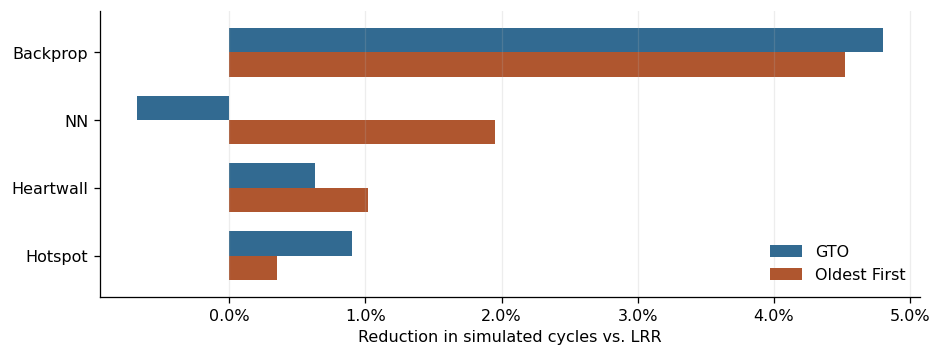

policy,workload,launch,kernel,instructions,GTO,LRR,Oldest First,Oldest − GTO
0,backprop,1,_Z22bpnn_layerforward_CUDAPfS_S_S_ii,6471680,7425,7698,7452,27
1,backprop,2,_Z24bpnn_adjust_weights_cudaPfiS_iS_S_,2818400,6582,7015,6596,14
2,heartwall,1,_Z6kernelv,6900708,8212,8264,8180,-32
3,hotspot,1,_Z14calculate_tempiPfS_iiiiffffff,4853274,7765,7911,7858,93
4,hotspot,2,_Z14calculate_tempiPfS_iiiiffffff,4853274,7894,8053,7949,55
5,hotspot,3,_Z14calculate_tempiPfS_iiiiffffff,4853274,7765,7819,7803,38
6,hotspot,4,_Z14calculate_tempiPfS_iiiiffffff,4853274,7775,7789,7813,38
7,hotspot,5,_Z14calculate_tempiPfS_iiiiffffff,4853274,7759,7805,7789,30
8,hotspot,6,_Z14calculate_tempiPfS_iiiiffffff,4853274,7782,7797,7793,11
9,hotspot,7,_Z14calculate_tempiPfS_iiiiffffff,3519728,7057,7113,7093,36


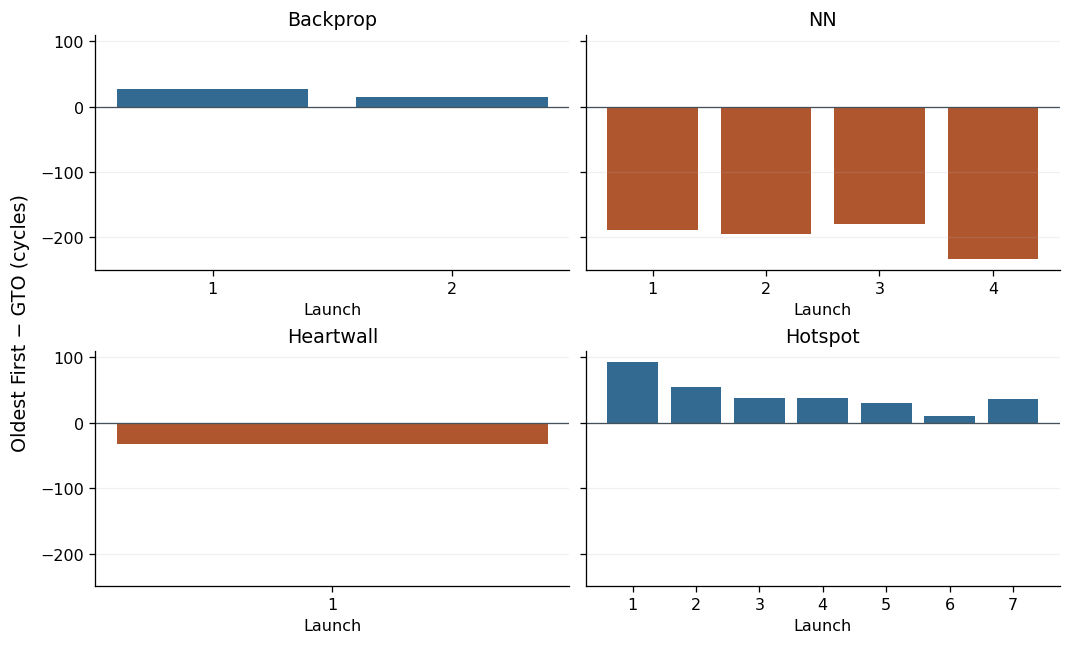

In [8]:
cycle_totals = data.pivot_table(index="workload", columns="policy", values="cycles", aggfunc="sum")
cycle_totals = cycle_totals.reindex(WORKLOADS)[["lrr", "gto", "oldest"]].astype(int)
savings = (1 - cycle_totals[["gto", "oldest"]].div(cycle_totals["lrr"], axis=0)) * 100

comparison = cycle_totals.rename(columns=POLICY_NAMES)
comparison["GTO reduction vs. LRR (%)"] = savings["gto"].round(3)
comparison["Oldest reduction vs. LRR (%)"] = savings["oldest"].round(3)
comparison["Oldest − GTO (cycles)"] = cycle_totals["oldest"] - cycle_totals["gto"]
display(comparison.rename(index=WORKLOAD_NAMES))

ax = savings.rename(index=WORKLOAD_NAMES, columns=POLICY_NAMES).plot.barh(
    figsize=(8.3, 3.2), color=[POLICY_COLORS["gto"], POLICY_COLORS["oldest"]], width=0.72
)
ax.invert_yaxis()
ax.set(xlabel="Reduction in simulated cycles vs. LRR", ylabel="")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.22)
plt.tight_layout()
plt.show()

launch_cycles = data.pivot(index=["workload", "launch", "kernel", "instructions"],
                          columns="policy", values="cycles").reset_index()
launch_cycles["Oldest − GTO"] = launch_cycles["oldest"] - launch_cycles["gto"]
display(launch_cycles.rename(columns=POLICY_NAMES))

fig, axes = plt.subplots(2, 2, figsize=(9.2, 5.5), sharey=True, layout="constrained")
for workload, ax in zip(WORKLOADS, axes.flat):
    rows = launch_cycles[launch_cycles["workload"].eq(workload)]
    difference = rows["Oldest − GTO"]
    ax.bar(rows["launch"], difference,
           color=[POLICY_COLORS["gto"] if value > 0 else POLICY_COLORS["oldest"] for value in difference])
    ax.axhline(0, color="#44515b", linewidth=0.8)
    ax.set(title=WORKLOAD_NAMES[workload], xticks=rows["launch"], xlabel="Launch")
    ax.grid(axis="y", alpha=0.18)
fig.supylabel("Oldest First − GTO (cycles)")
plt.show()

## Scheduler and load/store counters

Per-launch counts are differences of cumulative shader snapshots. Idle and scoreboard are scheduler outcomes. Load/store stalls are counted at a separate pipeline stage. Counter rates divide aggregated events by simulated GPU cycles. Archived counter coverage is NN and Hotspot.

,workload,policy,launch,cycles,idle,scoreboard,load/store stalls
10,nn,gto,1,7589,91939,350365,32073
11,nn,gto,2,7622,104364,334624,31577
12,nn,gto,3,7637,107390,332847,31397
13,nn,gto,4,7634,110836,329458,31437
14,nn,oldest,1,7400,88473,275170,33048
15,nn,oldest,2,7428,95105,279730,33631
16,nn,oldest,3,7458,98097,278855,33682
17,nn,oldest,4,7401,92976,274717,33651
28,hotspot,gto,1,7765,101326,368106,3827
29,hotspot,gto,2,7894,106174,388158,3876


,Idle (%),Scoreboard (%),Load/store stalls (%)
workload,,,
NN,-7.2,-15.52,8.79
Hotspot,8.59,-2.29,-0.27


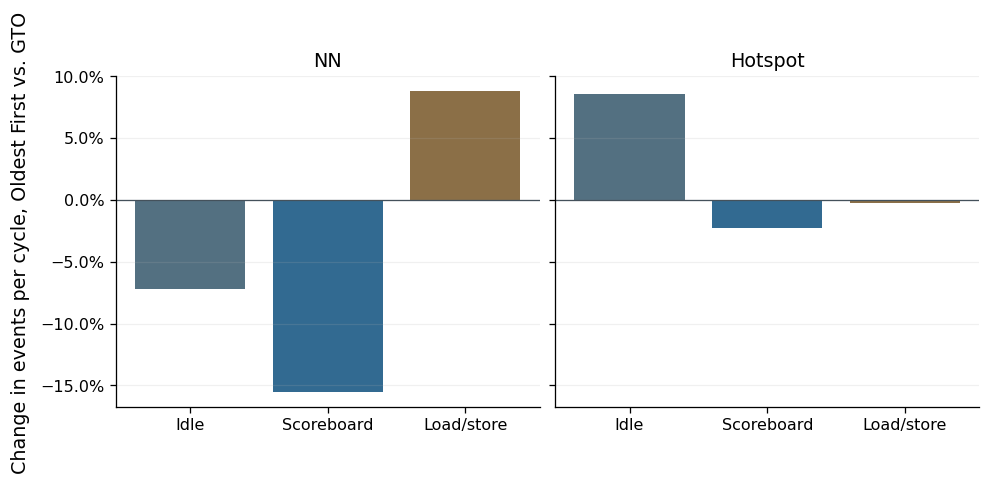

In [9]:
measured = data.dropna(subset=counter_names)
keys = ["workload", "policy", "launch", "cycles"]
display(measured[keys + counter_names].rename(columns={"ldst_stalls": "load/store stalls"}))

rates = measured.groupby(["workload", "policy"])[["cycles", *counter_names]].sum()
normalized = rates[counter_names].div(rates["cycles"], axis=0)
percent_delta = (normalized.xs("oldest", level="policy") /
                 normalized.xs("gto", level="policy") - 1) * 100
percent_delta = percent_delta.reindex([w for w in WORKLOADS if w in percent_delta.index])
display(percent_delta.rename(index=WORKLOAD_NAMES, columns={
    "idle": "Idle (%)", "scoreboard": "Scoreboard (%)", "ldst_stalls": "Load/store stalls (%)"
}).round(2))

fig, axes = plt.subplots(1, len(percent_delta), figsize=(8.5, 3.4), sharey=True, layout="constrained")
for ax, (workload, row) in zip(fig.axes, percent_delta.iterrows()):
    ax.bar(["Idle", "Scoreboard", "Load/store"], row, color=["#537081", "#326a91", "#8b6f47"])
    ax.axhline(0, color="#44515b", linewidth=0.8)
    ax.set_title(WORKLOAD_NAMES[workload])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.grid(axis="y", alpha=0.18)
fig.supylabel("Change in events per cycle, Oldest First vs. GTO")
plt.show()

[Validated whole-workload results](https://github.com/EnochWong521/gpu-warp-scheduling/blob/main/results/feasibility/results_validated.csv) · [Simulator issue logic](https://github.com/accel-sim/gpgpu-sim_distribution/blob/91880c53383d5a6a6742bfb1be2c5f34e39c7871/src/gpgpu-sim/shader.cc#L1477-L1795)

## Experiment summary and workload coverage

All runs use the SM7_QV100 trace-driven setup. Static WL4 is the feasibility policy `warp_limiting:2:4`. GTO limit 4 is the separate four-issue greedy-priority cap. Coverage counts validated launches, including measured runs whose override never fired.

In [10]:
results_root = input_path("results/feasibility/results_validated.csv").parent.parent
adaptive_root = results_root / "adaptive_policy"
figure_dir = results_root.parent / "plots" / "adaptive_policy"
figure_dir.mkdir(parents=True, exist_ok=True)

def export_figure(fig, stem):
    fig.savefig(figure_dir / f"{stem}.svg", facecolor="white")
    fig.savefig(figure_dir / f"{stem}.png", dpi=240, facecolor="white")
    plt.show()

feasibility = pd.read_csv(results_root / "feasibility/results_validated.csv").query('status == "PASS"')
suite = pd.read_csv(adaptive_root / "l1_guard_suite.csv").set_index("workload")
feasibility_stock = feasibility.query('scheduler == "gto"').set_index("workload")
pd.testing.assert_series_equal(suite.stock_cycles, feasibility_stock.cycles, check_names=False)
pd.testing.assert_series_equal(suite.launches, feasibility_stock.stat_blocks, check_names=False)
suite_names = {**WORKLOAD_NAMES, "bfs": "BFS", "nw": "NW", "lud": "LUD",
               "srad_v2": "SRAD v2", "pathfinder": "Pathfinder", "streamcluster": "Streamcluster"}
cap_cycles = experiment.groupby(["workload", "policy"]).cycles.sum().unstack()
override_cycles = load_runs.groupby(["workload", "enabled"]).cycles.sum().unstack()
bypass_totals = diag.groupby("workload")[["bypasses", "repeats"]].sum()
bypass_rate = 100 * bypass_totals.bypasses / bypass_totals.repeats
guard_delta = suite.guarded_cycles - suite.stock_cycles
geo = (suite.stock_cycles / suite.guarded_cycles).prod() ** (1 / len(suite))
summary = pd.DataFrame([
    ("Feasibility sweep", f"{len(feasibility)} validated runs on {len(suite)} workloads",
     f"{feasibility.scheduler.nunique()} policies per workload"),
    ("GTO limit 4", f"{experiment.groupby(['workload', 'policy']).ngroups} runs, {len(experiment)} launch rows",
     f"Cycles vs. GTO, NN {cap_cycles.loc['nn', 'gto_limit4'] - cap_cycles.loc['nn', 'gto']:+,}, "
     f"Hotspot {cap_cycles.loc['hotspot', 'gto_limit4'] - cap_cycles.loc['hotspot', 'gto']:+,}"),
    ("Stock GTO bypass and instruction pairs", f"{len(diag)} paired launches across NN and Hotspot",
     f"Bypasses per repeat, NN {bypass_rate.nn:.2f}%, Hotspot {bypass_rate.hotspot:.2f}%"),
    ("Unguarded load/load override", f"{len(load_runs)} launch rows across NN and Hotspot",
     f"Cycles vs. GTO, NN {override_cycles.loc['nn', 1] - override_cycles.loc['nn', 0]:+,}, "
     f"Hotspot {override_cycles.loc['hotspot', 1] - override_cycles.loc['hotspot', 0]:+,}"),
    ("NN load timing and writeback trace", "Two matched loads across stock and unguarded override",
     "CTA 5 added 371 cycles from L1 ready to eligibility"),
    ("Fixed zero-entry guard suite", f"{len(suite) * 3} runs, {suite.launches.sum()} launches per mode",
     f"{guard_delta.lt(0).sum()} wins, {guard_delta.gt(0).sum()} losses, {guard_delta.eq(0).sum()} ties "
     f"· {geo:.6f}× geometric-mean speedup"),
], columns=["Experiment", "Validated scope", "Measurement"])
display(summary)

coverage = feasibility.pivot(index="workload", columns="scheduler", values="stat_blocks")
coverage = coverage[["lrr", "gto", "rrr", "oldest", "wl4", "wl8", "wl16"]].rename(columns={
    **POLICY_NAMES, "gto": "Stock GTO", "rrr": "RRR",
    "wl4": "Static WL4", "wl8": "Static WL8", "wl16": "Static WL16"})
coverage["GTO limit 4"] = experiment.query('policy == "gto_limit4"').groupby("workload").size()
coverage["Unguarded load/load"] = suite.launches
coverage["Guarded load/load"] = suite.launches
display(coverage.reindex(suite.index).rename(index=suite_names)
        .astype("Int64").astype("string").fillna("Unmeasured"))

,Experiment,Validated scope,Measurement
0,Feasibility sweep,70 validated runs on 10 workloads,7 policies per workload
1,GTO limit 4,"8 runs, 44 launch rows","Cycles vs. GTO, NN +38, Hotspot +29"
2,Stock GTO bypass and instruction pairs,11 paired launches across NN and Hotspot,"Bypasses per repeat, NN 5.74%, Hotspot 13.75%"
3,Unguarded load/load override,22 launch rows across NN and Hotspot,"Cycles vs. GTO, NN +79, Hotspot +0"
4,NN load timing and writeback trace,Two matched loads across stock and unguarded o...,CTA 5 added 371 cycles from L1 ready to eligib...
5,Fixed zero-entry guard suite,"30 runs, 193 launches per mode","5 wins, 2 losses, 3 ties · 1.000067× geometric..."


scheduler,LRR,Stock GTO,RRR,Oldest First,Static WL4,Static WL8,Static WL16,GTO limit 4,Unguarded load/load,Guarded load/load
workload,,,,,,,,,,
BFS,16,16,16,16,16,16,16,Unmeasured,16,16
NW,15,15,15,15,15,15,15,Unmeasured,15,15
NN,4,4,4,4,4,4,4,4,4,4
LUD,10,10,10,10,10,10,10,Unmeasured,10,10
SRAD v2,4,4,4,4,4,4,4,Unmeasured,4,4
Hotspot,7,7,7,7,7,7,7,7,7,7
Backprop,2,2,2,2,2,2,2,Unmeasured,2,2
Heartwall,1,1,1,1,1,1,1,Unmeasured,1,1
Pathfinder,4,4,4,4,4,4,4,Unmeasured,4,4


## NN launch 2 · CTA 5 · matched promoted load

Warp 0, load 1, PC `0xb0`. L1 response ready means the fill made the MSHR entry ready. Writeback eligibility additionally requires the sector at the head of the ready queue and an open writeback latch. Both runs selected the gating sector at first eligibility.

,Issue,LD/ST entry,Gating-sector admission,L1 response ready,Writeback eligible,Selected,Scoreboard clear
mode,,,,,,,
Stock GTO,5229,5279,5284,5613,6218,6218,6219
Unguarded override,5336,5360,5365,5716,6692,6692,6693


,Issue to LD/ST entry,Entry to admission,Admission to L1 ready,L1 ready to eligible,Eligible to selected,Selected to clear,Issue to clear
mode,,,,,,,
Stock GTO,50,5,329,605,0,1,NaN
Unguarded override,24,5,351,976,0,1,NaN


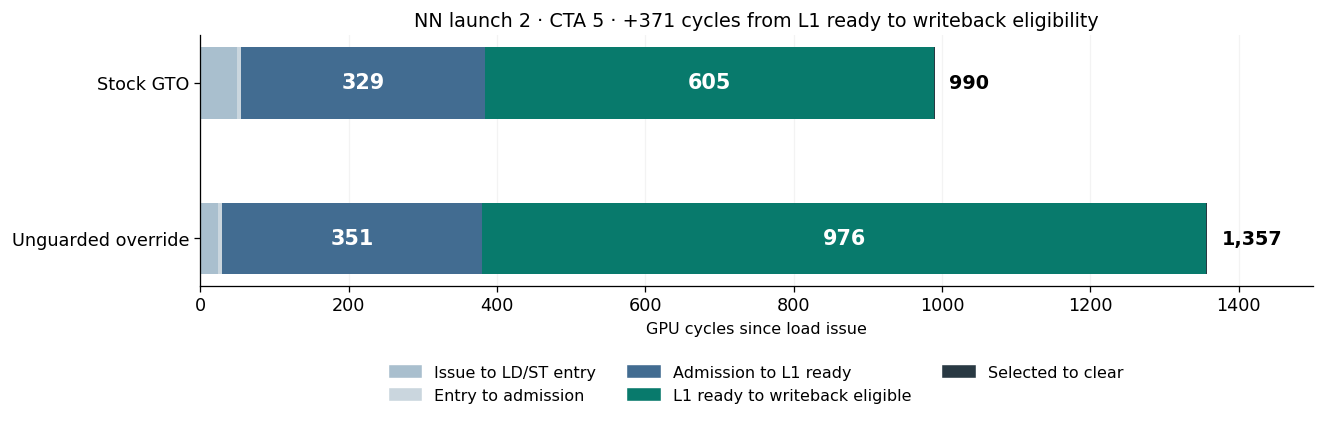

In [11]:
writeback_run = adaptive_root / "nn_writeback_pressure.KLmiLQ2o"
load_match = pd.read_csv(adaptive_root / "nn_load_timing.csv").query(
    'launch == 2 and cta_x == 5 and cta_y == 0 and cta_z == 0 and warp == 0 '
    'and load_ordinal == 1 and role == "promoted"')
assert len(load_match) == 1 and load_match.iloc[0].pc == "0xb0"
match = load_match.iloc[0]
modes_cta = ["stock", "enabled"]
stages_cta = pd.read_csv(writeback_run / "nn_memory_stages.csv").query(
    'launch == 2 and cta == 5 and pc == "0xb0"').set_index("mode").loc[modes_cta]
split_cta = pd.read_csv(writeback_run / "nn_writeback_split.csv").query(
    "launch == 2 and cta == 5").set_index("mode").loc[modes_cta]
assert split_cta.address.tolist() == stages_cta.gating_address.tolist()
assert split_cta.ready.tolist() == stages_cta.gating_response.tolist()
assert split_cta.selected.tolist() == stages_cta.gating_writeback_pick.tolist()
assert split_cta.first_eligible.equals(split_cta.selected)
assert split_cta[["head_latch_busy", "eligible_unselected"]].eq(0).all().all()
for mode in modes_cta:
    assert stages_cta.loc[mode, "issue"] == match[f"{mode}_issue"]
    assert stages_cta.loc[mode, "clear"] == match[f"{mode}_clear"]

timeline = pd.DataFrame({
    "Issue": stages_cta.issue, "LD/ST entry": stages_cta.entry,
    "Gating-sector admission": stages_cta.gating_admit, "L1 response ready": split_cta.ready,
    "Writeback eligible": split_cta.first_eligible, "Selected": split_cta.selected,
    "Scoreboard clear": stages_cta.clear,
})
mode_names = {"stock": "Stock GTO", "enabled": "Unguarded override"}
display(timeline.rename(index=mode_names))
durations = timeline.diff(axis=1).iloc[:, 1:].astype(int).rename(columns={
    "LD/ST entry": "Issue to LD/ST entry", "Gating-sector admission": "Entry to admission",
    "L1 response ready": "Admission to L1 ready", "Writeback eligible": "L1 ready to eligible",
    "Selected": "Eligible to selected", "Scoreboard clear": "Selected to clear"})
assert durations.loc["enabled", "L1 ready to eligible"] - durations.loc["stock", "L1 ready to eligible"] == 371
assert durations.sum(axis=1).tolist() == [990, 1357]
display(durations.rename(index=mode_names).assign(**{"Issue to clear": durations.sum(axis=1)}))

fig, ax = plt.subplots(figsize=(11.4, 3.55), layout="constrained")
colors_cta = ["#a9bfce", "#cad6de", "#426c91", "#087a6c", "#dce3e9", "#293943"]
left = [0, 0]
for col, color in zip(durations, colors_cta):
    bars = ax.barh(list(mode_names.values()), durations[col], left=left, height=0.46, color=color)
    for bar, value in zip(bars, durations[col]):
        if value >= 250:
            ax.text(bar.get_x() + value / 2, bar.get_y() + bar.get_height() / 2, f"{value:,}",
                    ha="center", va="center", color="white", fontsize=13, fontweight="bold")
    left = [base + value for base, value in zip(left, durations[col])]
for y, value in enumerate(left):
    ax.text(value + 20, y, f"{value:,}", va="center", fontsize=12, fontweight="bold")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=colors_cta[0], label="Issue to LD/ST entry"),
                   Patch(color=colors_cta[1], label="Entry to admission"),
                   Patch(color=colors_cta[2], label="Admission to L1 ready"),
                   Patch(color=colors_cta[3], label="L1 ready to writeback eligible"),
                   Patch(color=colors_cta[-1], label="Selected to clear")],
          loc="upper center", bbox_to_anchor=(0.5, -0.26), ncols=3, frameon=False)
ax.set(xlim=(0, 1500), xlabel="GPU cycles since load issue",
       title="NN launch 2 · CTA 5 · +371 cycles from L1 ready to writeback eligibility")
ax.tick_params(labelsize=11)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
export_figure(fig, "nn_cta5_memory_stages")

## Fixed guard suite

Negative cycle changes favor the variant. Inactive means zero qualifying guarded decisions. Pathfinder took 15 overrides and tied stock in total cycles.

,launches,stock_cycles,unguarded_cycles,guarded_cycles,guarded_taken,guarded_suppressed,guarded_pct_change,Unguarded,Zero-entry guard
workload,,,,,,,,,
BFS,16,115226,115212,115212,63,4,-0.012150,-0.0122,-0.0122
NW,15,133487,133487,133487,0,0,0.000000,0.0000,0.0000
NN,4,30482,30561,30476,423,547,-0.019684,0.2592,-0.0197
LUD,10,135773,135749,135749,19,0,-0.017677,-0.0177,-0.0177
SRAD v2,4,29230,29218,29218,2944,0,-0.041054,-0.0411,-0.0411
Hotspot,7,53797,53797,53797,0,0,0.000000,0.0000,0.0000
Backprop,2,14007,14069,14008,2003,225,0.007139,0.4426,0.0071
Heartwall,1,8212,8194,8204,262,14,-0.097418,-0.2192,-0.0974
Pathfinder,4,29109,29109,29109,15,0,0.000000,0.0000,0.0000


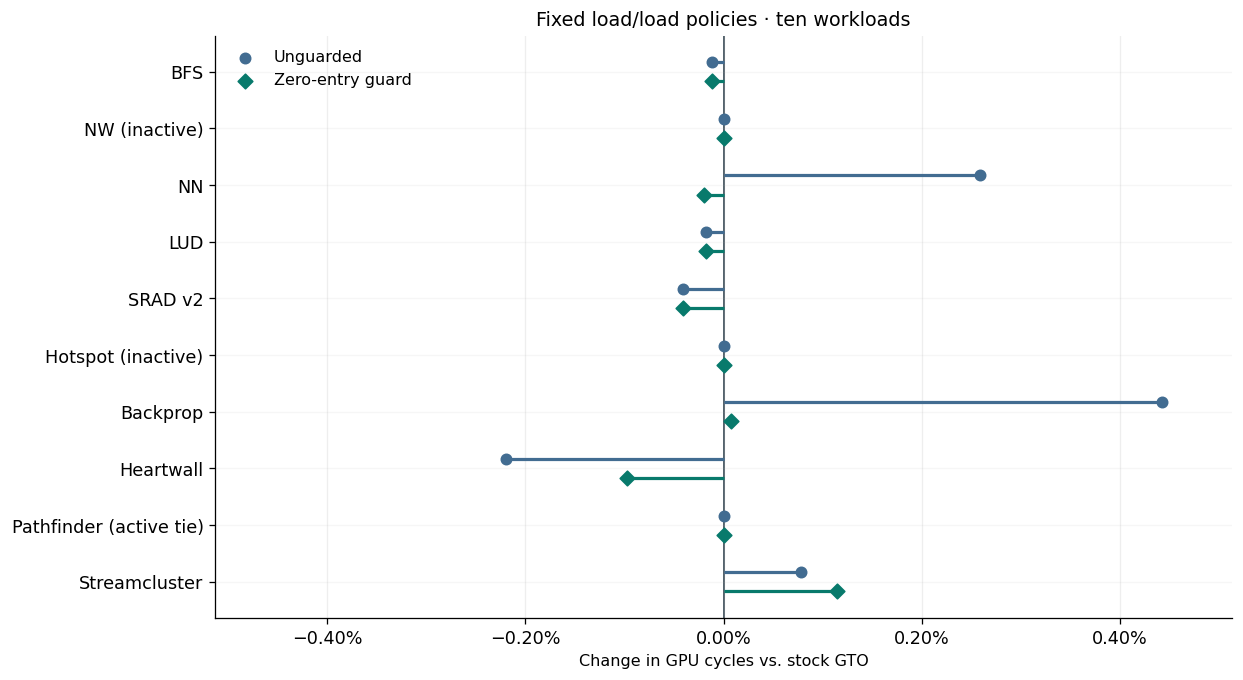

In [12]:
variants = {"Unguarded": "unguarded_cycles", "Zero-entry guard": "guarded_cycles"}
suite_pct = pd.DataFrame({
    label: (suite[col] - suite.stock_cycles) / suite.stock_cycles * 100
    for label, col in variants.items()
})
assert (suite_pct["Zero-entry guard"] - suite.guarded_pct_change).abs().lt(0.000001).all()
inactive = suite.guarded_taken.add(suite.guarded_suppressed).eq(0)
active_tie = suite.guarded_cycles.eq(suite.stock_cycles) & ~inactive
labels = [
    suite_names[w] + (" (inactive)" if inactive[w] else " (active tie)" if active_tie[w] else "")
    for w in suite.index
]
display(suite.join(suite_pct.round(4)).rename(index=suite_names))

fig, ax = plt.subplots(figsize=(10.7, 5.8), layout="constrained")
positions = list(range(len(labels)))
for (label, values), offset, color, marker in zip(
        suite_pct.items(), [-0.17, 0.17], ["#426c91", "#087a6c"], ["o", "D"]):
    y = [pos + offset for pos in positions]
    ax.hlines(y, 0, values, color=color, linewidth=2)
    ax.scatter(values, y, label=label, marker=marker, color=color, s=42, zorder=3)
extent = suite_pct.abs().to_numpy().max()
limit = max(0.1, extent * 1.16)
ax.axvline(0, color="#283b47", linewidth=1, zorder=1)
ax.set(yticks=positions, yticklabels=labels, xlim=(-limit, limit),
       xlabel="Change in GPU cycles vs. stock GTO", title="Fixed load/load policies · ten workloads")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=2))
ax.invert_yaxis()
ax.tick_params(labelsize=11)
ax.grid(axis="x", alpha=0.21)
ax.grid(axis="y", alpha=0.1)
ax.legend(loc="upper left", frameon=False)
export_figure(fig, "l1_guard_suite_cycle_change")

## Streamcluster signed launch deltas

All 130 launches run `pgain_kernel`. Bars show guarded cycles minus the named reference, so a positive bar is a slowdown.

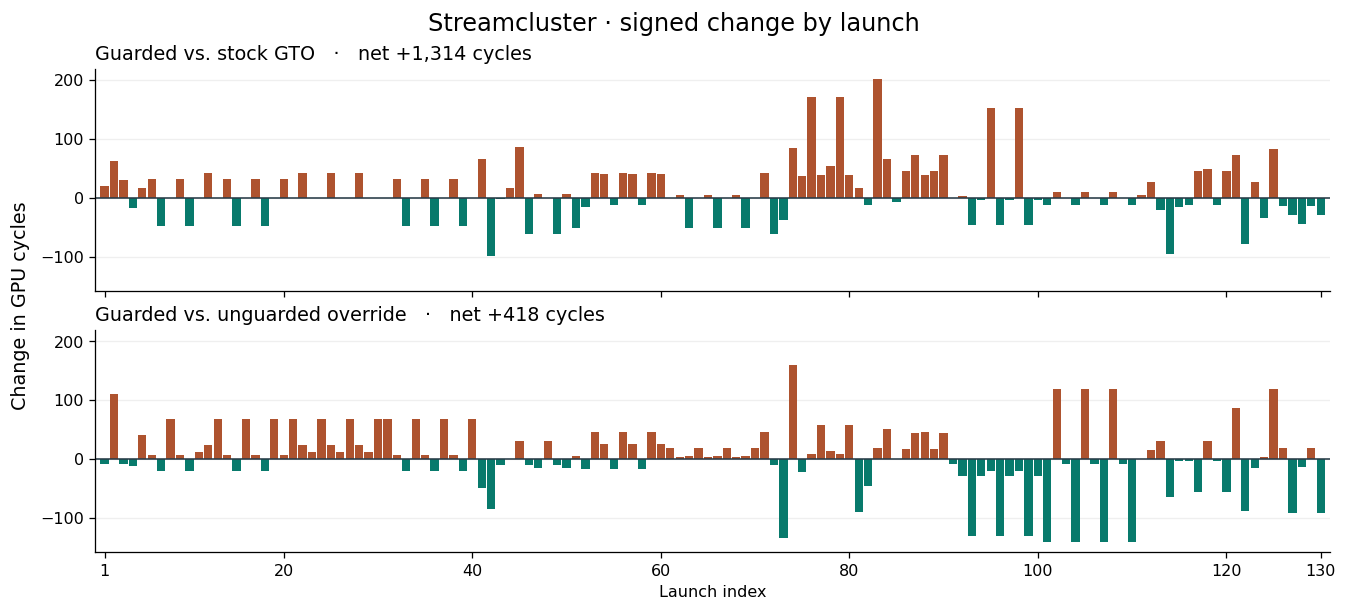

In [13]:
sc = pd.read_csv(adaptive_root / "streamcluster_l1_guard_launches.csv").sort_values("launch")
assert sc.launch.tolist() == list(range(1, int(suite.loc["streamcluster", "launches"]) + 1))
assert sc.kernel.nunique() == 1
for base, expected in [("stock", 1314), ("unguarded", 418)]:
    delta = sc.guarded_cycles - sc[f"{base}_cycles"]
    assert delta.equals(sc[f"delta_{base}"]) and delta.sum() == expected
for col in ("stock_cycles", "unguarded_cycles", "guarded_cycles"):
    assert sc[col].sum() == suite.loc["streamcluster", col]

fig, axes = plt.subplots(2, 1, sharex=True, sharey=True, figsize=(11.6, 5.2), layout="constrained")
colors_sc = {True: "#ae532f", False: "#087a6c"}
for ax, (col, label) in zip(axes, [("delta_stock", "stock GTO"), ("delta_unguarded", "unguarded override")]):
    delta = sc[col]
    ax.bar(sc.launch, delta, color=[colors_sc[value > 0] for value in delta], width=0.88)
    ax.axhline(0, color="#283b47", linewidth=1)
    ax.set_title(f"Guarded vs. {label}   ·   net {delta.sum():+,} cycles", loc="left", fontsize=12)
    ax.grid(axis="y", alpha=0.20)
    ax.set_axisbelow(True)
axes[-1].set(xlabel="Launch index", xlim=(0, 131), xticks=[1, 20, 40, 60, 80, 100, 120, 130])
fig.supylabel("Change in GPU cycles")
fig.suptitle("Streamcluster · signed change by launch", fontsize=15)
export_figure(fig, "streamcluster_signed_launch_deltas")